# ¿A quién se parece Colombia? Perfiles macroeconómicos con ACP y K-Means

**Taller individual · Machine Learning aplicado a Economía y Finanzas · Pontificia Universidad Javeriana Cali**
Giuliano Stiven Vera Campo

Este cuaderno reproduce paso a paso el análisis que ejecuta la aplicación de Streamlit (`app.py`). Usa exactamente
el mismo código (`src/pipeline.py`) y los mismos datos (`data/`), así que las tablas y cifras coinciden con la app.

**Pregunta:** ¿con qué economías comparte Colombia su perfil macroeconómico y de desarrollo, y ese parecido coincide
con su región o con su nivel de ingreso?

**Cómo ejecutarlo**
- **En Colab:** abre el cuaderno desde el botón *Open in Colab* del README y ejecuta *Entorno de ejecución → Ejecutar todas*. La primera celda clona el repositorio.
- **En local:** desde la raíz del repositorio, `pip install -r requirements.txt` y `jupyter notebook analisis_paso_a_paso.ipynb`.

## 0. Configuración del entorno

In [1]:
# Si el cuaderno se ejecuta fuera del repositorio (por ejemplo en Colab), clona el repositorio
# para tener el código (src/) y los datos (data/). Reemplaza la URL por la de tu repositorio.
REPO_URL = "https://github.com/stivenv6/ACP---K-means--pa-ses.git"

import os, sys, subprocess
from pathlib import Path

if not Path("src/pipeline.py").exists():
    carpeta = Path(REPO_URL.rstrip("/").split("/")[-1].replace(".git", ""))
    if not carpeta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir(carpeta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# Si faltaran los CSV, se regeneran desde la fuente original
if not Path("data/wdi_panel_paises.csv").exists():
    subprocess.run([sys.executable, "scripts/descargar_datos.py"], check=True)

sys.path.insert(0, str(Path.cwd()))
print("Directorio de trabajo:", Path.cwd())

Directorio de trabajo: /home/claude/proyecto


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew

from src import pipeline as pl
from src.config import VARIABLES, VARIABLES_DEFECTO, TRANSFORMACIONES, UMBRAL_FALTANTES, nombre, descripcion

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
AZUL, NARANJA = "#1d5c7a", "#d9822b"
COLORES = ["#1d5c7a", "#d9822b", "#4f9d69", "#a23b72", "#7a6c5d", "#3fa7d6"]

# Configuración de referencia (la misma que la app trae por defecto)
PERIODO = (2015, 2019)
N_COMP = 4
K = 4

## 1. Los datos

**Fuente:** *World Development Indicators* (WDI) del Banco Mundial, en la copia pública y versionada que mantiene
la Fundación Gapminder en GitHub (`open-numbers/ddf--open_numbers--world_development_indicators`). El script
`scripts/descargar_datos.py` reconstruye los dos archivos de `data/`.

**Cobertura:** 195 Estados de la ONU (193 miembros más Palestina y la Santa Sede, observadores), panel anual 2010–2025. Cada variable puede verificarse en
`https://data.worldbank.org/indicator/<CÓDIGO>`.

In [3]:
panel, meta = pl.cargar_datos()
print(f"Panel país-año: {panel.shape[0]} filas × {panel.shape[1]} columnas")
print(f"Países: {panel['iso3'].nunique()} · Años: {panel['anio'].min()}–{panel['anio'].max()}")
print(f"Duplicados país-año: {pl.duplicados(panel)}")
panel.head()

Panel país-año: 3104 filas × 19 columnas
Países: 194 · Años: 2010–2025
Duplicados país-año: 0


,iso3,anio,pib_pc,crec_pib,inflacion,desempleo,comercio,ied,cuenta_corriente,formacion_capital,credito_privado,esperanza_vida,urbanizacion,internet,gasto_salud,gasto_educacion,deuda_publica,recaudo,poblacion
0,AFG,2010,542.87103,14.36244,2.17854,7.809,NaN,1.20312,-3.64331,NaN,11.57504,60.702,22.26148,4.0000,8.56967,3.47945,NaN,9.16975,28284089
1,AFG,2011,525.42698,0.42635,11.80419,7.830,NaN,0.29303,-12.61954,NaN,4.95918,61.250,22.82057,5.0000,8.56191,3.46201,NaN,8.91679,29347708
2,AFG,2012,568.92902,12.75229,6.44121,7.875,NaN,0.28544,-25.87068,NaN,4.47210,61.735,23.34344,5.4545,7.89717,2.60421,NaN,7.70780,30560034
3,AFG,2013,580.60383,5.60074,7.38577,7.921,NaN,0.23980,-25.29006,NaN,4.32169,62.188,23.80771,5.9000,8.80596,3.45446,NaN,7.12277,31622704
4,AFG,2014,575.14625,2.72454,4.67400,7.915,NaN,0.20966,-15.77242,NaN,3.94106,62.260,24.19102,7.0000,9.52888,3.69522,NaN,6.88210,32792523


In [4]:
# Variables: código WDI, descripción y transformación prevista
pd.DataFrame([{"Clave": k, "Código WDI": v[0], "Descripción": v[2], "Dimensión": v[3],
               "En el modelo": k in VARIABLES_DEFECTO,
               "Transformación": TRANSFORMACIONES.get(k, "—")} for k, v in VARIABLES.items()])

,Clave,Código WDI,Descripción,Dimensión,En el modelo,Transformación
0,pib_pc,NY.GDP.PCAP.KD,PIB per cápita (US$ constantes de 2015),Ingreso,True,log
1,crec_pib,NY.GDP.MKTP.KD.ZG,Crecimiento del PIB real (% anual),Dinamismo,True,winsor
2,inflacion,FP.CPI.TOTL.ZG,"Inflación, precios al consumidor (% anual)",Estabilidad,True,winsor
3,desempleo,SL.UEM.TOTL.ZS,"Desempleo (% de la fuerza laboral, estimación ...",Mercado laboral,True,—
4,comercio,NE.TRD.GNFS.ZS,Exportaciones + importaciones (% del PIB),Apertura,True,log
5,ied,BX.KLT.DINV.WD.GD.ZS,"Inversión extranjera directa, entradas netas (...",Apertura,True,winsor
6,cuenta_corriente,BN.CAB.XOKA.GD.ZS,Saldo de la cuenta corriente (% del PIB),Sector externo,True,winsor
7,formacion_capital,NE.GDI.TOTL.ZS,Formación bruta de capital (% del PIB),Inversión,True,—
8,credito_privado,FS.AST.PRVT.GD.ZS,Crédito interno al sector privado (% del PIB),Profundidad financiera,True,log
9,esperanza_vida,SP.DYN.LE00.IN,Esperanza de vida al nacer (años),Desarrollo humano,True,—


In [5]:
# Tipos de cada columna: iso3 es un identificador y no entra al modelo; anio solo se usa para promediar
panel.dtypes.to_frame("tipo").T

,iso3,anio,pib_pc,crec_pib,inflacion,desempleo,comercio,ied,cuenta_corriente,formacion_capital,credito_privado,esperanza_vida,urbanizacion,internet,gasto_salud,gasto_educacion,deuda_publica,recaudo,poblacion
tipo,str,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64


## 2. Exploración

Cada país se resume con el **promedio del periodo 2015–2019** (antes de la pandemia). Un valor solo se calcula si el
país tiene al menos 3 años con dato. Luego se excluyen los países con menos de 1 millón de habitantes, cuyos perfiles
extremos de comercio o turismo distorsionarían las distancias.

In [6]:
df = pl.promediar_periodo(panel, meta, *PERIODO)
prep = pl.preparar(df, VARIABLES_DEFECTO)        # filtro de tamaño, faltantes, imputación, transformación, estandarización
base = prep.base_tamano                           # países tras el filtro de tamaño, antes de tratar faltantes
print(f"Países tras el filtro de tamaño: {len(base)} (excluidos: {len(prep.paises_excluidos_tamano)})")

desc = base[list(VARIABLES)].describe().T
desc["asimetría"] = [skew(base[v].dropna()) for v in desc.index]
desc.index = [nombre(v) for v in desc.index]
desc.round(2)

Países tras el filtro de tamaño: 158 (excluidos: 37)


,count,mean,std,min,25%,50%,75%,max,asimetría
PIB per cápita,154.0,12796.85,17740.15,262.42,1509.11,4933.87,14784.11,87018.43,1.99
Crecimiento del PIB,154.0,3.05,3.06,-17.25,1.77,3.18,4.73,9.72,-2.54
Inflación,148.0,5.57,14.25,-0.26,1.12,2.14,5.28,158.27,8.74
Desempleo,157.0,7.61,5.91,0.13,3.68,5.38,10.31,26.82,1.37
Comercio exterior,144.0,80.31,46.14,19.90,50.10,66.93,98.55,319.24,2.07
IED,152.0,4.58,17.65,-3.64,1.27,2.56,4.06,215.20,11.32
Cuenta corriente,144.0,-2.60,6.31,-26.77,-4.69,-2.28,0.84,17.27,-0.43
Formación de capital,143.0,24.41,7.63,2.83,20.14,23.52,27.20,49.87,0.64
Crédito privado,144.0,52.63,42.89,2.33,19.29,40.56,67.54,188.37,1.20
Esperanza de vida,157.0,71.50,8.43,44.37,65.13,72.96,77.81,84.09,-0.62


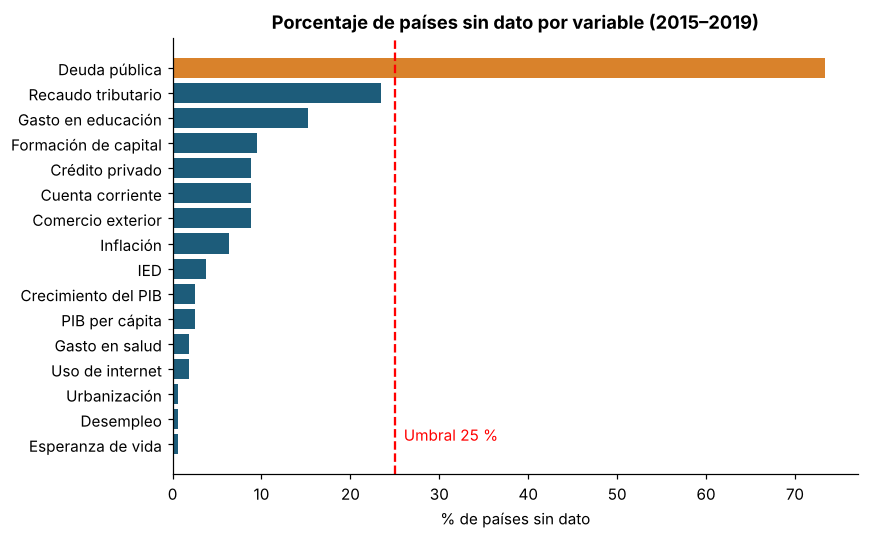

,Variable,Código WDI,Países sin dato,% faltante,Decisión
14,Deuda pública,GC.DOD.TOTL.GD.ZS,116,73.4,Excluir (supera el umbral)
15,Recaudo tributario,GC.TAX.TOTL.GD.ZS,37,23.4,Conservar
13,Gasto en educación,SE.XPD.TOTL.GD.ZS,24,15.2,Conservar
7,Formación de capital,NE.GDI.TOTL.ZS,15,9.5,Conservar
8,Crédito privado,FS.AST.PRVT.GD.ZS,14,8.9,Conservar
4,Comercio exterior,NE.TRD.GNFS.ZS,14,8.9,Conservar
6,Cuenta corriente,BN.CAB.XOKA.GD.ZS,14,8.9,Conservar
2,Inflación,FP.CPI.TOTL.ZG,10,6.3,Conservar
5,IED,BX.KLT.DINV.WD.GD.ZS,6,3.8,Conservar
0,PIB per cápita,NY.GDP.PCAP.KD,4,2.5,Conservar


In [7]:
# Datos faltantes por variable
falt = pl.tabla_faltantes(base, list(VARIABLES))
fig, ax = plt.subplots(figsize=(8, 5))
f = falt.sort_values("% faltante")
ax.barh(f["Variable"], f["% faltante"], color=[NARANJA if d.startswith("Excluir") else AZUL for d in f["Decisión"]])
ax.axvline(100 * UMBRAL_FALTANTES, ls="--", color="red")
ax.text(100 * UMBRAL_FALTANTES + 1, 0, f"Umbral {int(100*UMBRAL_FALTANTES)} %", color="red", va="bottom")
ax.set(title="Porcentaje de países sin dato por variable (2015–2019)", xlabel="% de países sin dato")
plt.tight_layout(); plt.show()
falt[["Variable", "Código WDI", "Países sin dato", "% faltante", "Decisión"]].round(1)

La **deuda pública** supera ampliamente el umbral (a casi tres de cada cuatro países les falta) y se descarta. El
**recaudo tributario** queda cerca del umbral y no se incluye por defecto. Los faltantes se concentran en países en
conflicto o con estadísticas débiles: **no son aleatorios**, lo que se reconoce como limitación.

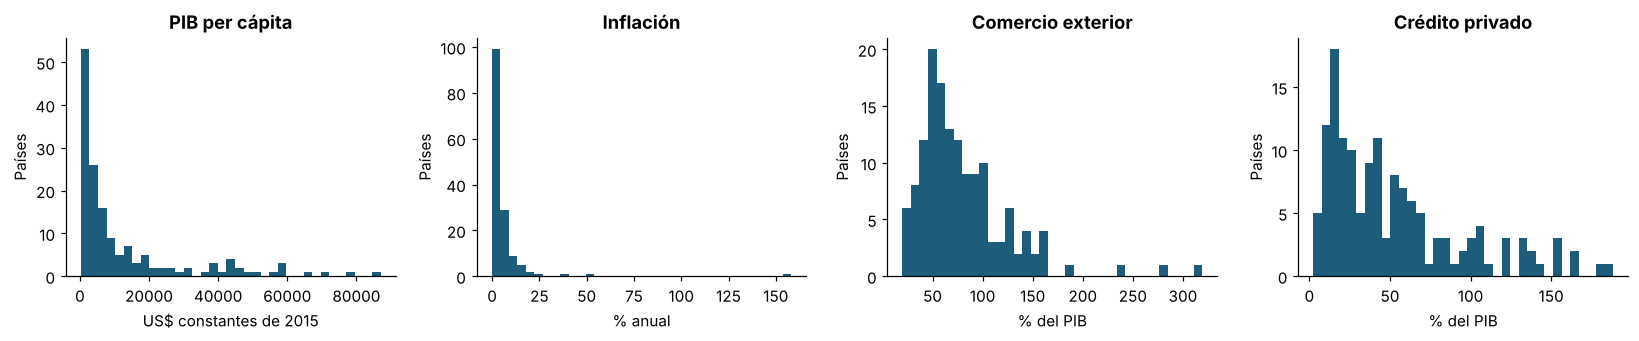

In [8]:
# Distribuciones de las variables más asimétricas
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, v in zip(axes, ["pib_pc", "inflacion", "comercio", "credito_privado"]):
    ax.hist(base[v].dropna(), bins=35, color=AZUL)
    ax.set(title=nombre(v), xlabel=descripcion(v).split("(")[-1].rstrip(")"), ylabel="Países")
plt.tight_layout(); plt.show()

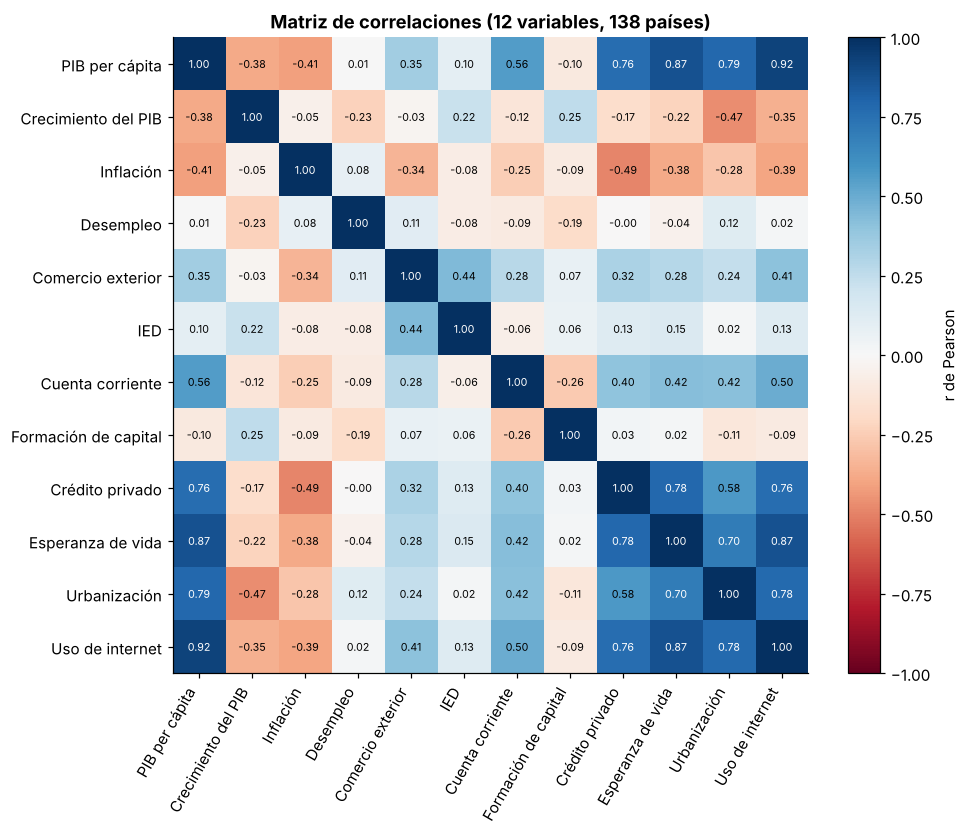

In [9]:
# Matriz de correlaciones de las 12 variables del modelo (ya transformadas)
corr = prep.transformadas.corr()
etiquetas = [nombre(v) for v in corr.columns]
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=60, ha="right")
ax.set_yticks(range(len(etiquetas)), etiquetas)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="r de Pearson")
ax.set_title(f"Matriz de correlaciones ({len(corr.columns)} variables, {len(prep.transformadas)} países)")
plt.tight_layout(); plt.show()

PIB per cápita, uso de internet, esperanza de vida, crédito privado y urbanización tienen correlaciones de 0,7–0,9:
miden en buena parte lo mismo (el nivel de desarrollo). Crecimiento, IED y formación de capital se correlacionan poco
con ese bloque. Esta redundancia es la razón para aplicar ACP antes de agrupar.

## 3. Preparación

1. Variables con más de 25 % de faltantes: se excluyen.
2. Países a los que les falta **una sola** variable: se imputa la mediana de su grupo de ingreso del Banco Mundial.
3. Países con dos o más faltantes: se excluyen.
4. Logaritmo para variables positivas muy sesgadas; winsorización 2,5–97,5 % para colas extremas.
5. Estandarización (media 0, desviación 1), porque ACP y K-Means dependen de escalas y distancias.

In [10]:
print(f"Variables excluidas por faltantes: {prep.excluidas_faltantes or 'ninguna'}")
print(f"Países excluidos por faltantes ({len(prep.paises_excluidos_faltantes)}):",
      ", ".join(df.loc[prep.paises_excluidos_faltantes, 'pais']))
print(f"\nMuestra final: {len(prep.estandarizadas)} países × {len(prep.variables)} variables")
print(f"\nPaíses imputados ({len(prep.imputados)}):")
prep.imputados.drop(columns="iso3")

Variables excluidas por faltantes: ninguna
Países excluidos por faltantes (20): Afganistán, Burundi, Cuba, Eritrea, Ciudad del Vaticano, Irán, Jamaica, Jordania, Laos, Liberia, Myanmar (Birmania), Nigeria, Papúa Nueva Guinea, Corea del Norte, Somalia, Sudán del Sur, Siria, Turkmenistán, Venezuela, Yemen

Muestra final: 138 países × 12 variables

Países imputados (12):


,País,Variable imputada,Valor imputado,Referencia
0,Emiratos Árabes Unidos,Cuenta corriente,0.87,Ingreso alto
1,Argentina,Inflación,2.74,Ingreso medio-alto
2,Baréin,Crédito privado,84.48,Ingreso alto
3,República Centroafricana,Cuenta corriente,-5.41,Ingreso bajo
4,Canadá,Crédito privado,84.48,Ingreso alto
5,República Democrática del Congo,Inflación,5.31,Ingreso bajo
6,Etiopía,Crédito privado,12.82,Ingreso bajo
7,Gabón,Cuenta corriente,-2.06,Ingreso medio-alto
8,Guinea Ecuatorial,Cuenta corriente,-2.06,Ingreso medio-alto
9,Libia,IED,2.75,Ingreso medio-alto


In [11]:
# Efecto de las transformaciones sobre la asimetría
pd.DataFrame({"Variable": [nombre(v) for v in prep.variables],
              "Regla": [TRANSFORMACIONES.get(v, "—") for v in prep.variables],
              "Asimetría original": [skew(prep.originales[v]) for v in prep.variables],
              "Asimetría transformada": [skew(prep.transformadas[v]) for v in prep.variables]}).round(2)

,Variable,Regla,Asimetría original,Asimetría transformada
0,PIB per cápita,log,1.83,0.04
1,Crecimiento del PIB,winsor,-0.53,0.05
2,Inflación,winsor,4.48,1.80
3,Desempleo,—,1.46,1.46
4,Comercio exterior,log,2.03,0.22
5,IED,winsor,10.81,2.19
6,Cuenta corriente,winsor,-0.52,-0.16
7,Formación de capital,—,0.94,0.94
8,Crédito privado,log,1.12,-0.26
9,Esperanza de vida,—,-0.59,-0.59


In [12]:
# Verificación de la estandarización
pd.DataFrame({"Media": prep.estandarizadas.mean(), "Desv. estándar": prep.estandarizadas.std(ddof=0)}).round(3).T

,pib_pc,crec_pib,inflacion,desempleo,comercio,ied,cuenta_corriente,formacion_capital,credito_privado,esperanza_vida,urbanizacion,internet
Media,-0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,0.0
Desv. estándar,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 4. Análisis de Componentes Principales

In [13]:
acp = pl.ejecutar_acp(prep.estandarizadas)
v = acp.varianza
print(f"Criterio de Kaiser (λ > 1): {acp.n_kaiser} componentes · ≥70 %: {acp.n_70} · ≥80 %: {acp.n_80}")
v.round(2)

Criterio de Kaiser (λ > 1): 4 componentes · ≥70 %: 4 · ≥80 %: 5


,Componente,Valor propio,% varianza,% acumulado
0,CP1,5.03,41.58,41.58
1,CP2,1.76,14.56,56.14
2,CP3,1.21,9.98,66.12
3,CP4,1.01,8.36,74.48
4,CP5,0.84,6.93,81.40
5,CP6,0.64,5.27,86.68
6,CP7,0.60,4.94,91.62
7,CP8,0.34,2.85,94.47
8,CP9,0.30,2.44,96.91
9,CP10,0.20,1.68,98.59


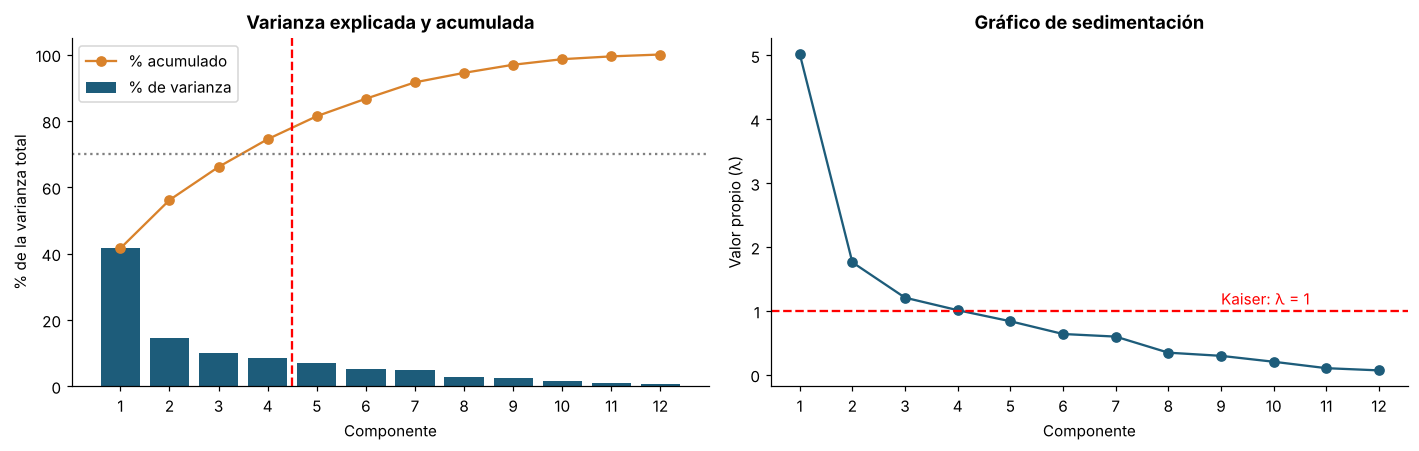

In [14]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(1, len(v) + 1)
a1.bar(x, v["% varianza"], color=AZUL, label="% de varianza")
a1.plot(x, v["% acumulado"], "o-", color=NARANJA, label="% acumulado")
a1.axhline(70, ls=":", color="gray"); a1.axvline(N_COMP + 0.5, ls="--", color="red")
a1.set(title="Varianza explicada y acumulada", xlabel="Componente", ylabel="% de la varianza total", xticks=x)
a1.legend()
a2.plot(x, v["Valor propio"], "o-", color=AZUL)
a2.axhline(1, ls="--", color="red"); a2.text(len(v) - 3, 1.1, "Kaiser: λ = 1", color="red")
a2.set(title="Gráfico de sedimentación", xlabel="Componente", ylabel="Valor propio (λ)", xticks=x)
plt.tight_layout(); plt.show()

**Se conservan 4 componentes:** son los que tienen valor propio mayor que 1 (resumen más que una variable original) y
acumulan el 74,5 % de la varianza, por encima del 70 %. El CP1 solo explica el 42 %: reducir todo a un eje de "ingreso"
dejaría por fuera más de la mitad de la información.

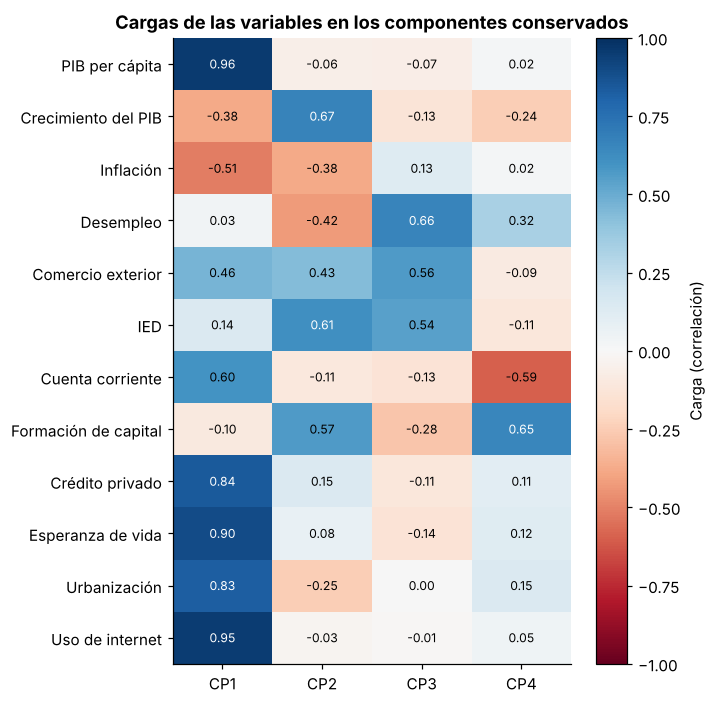

In [15]:
# Cargas expresadas como correlaciones entre cada variable y cada componente
cargas = acp.cargas.iloc[:, :N_COMP].copy()
cargas.index = [nombre(i) for i in cargas.index]
fig, ax = plt.subplots(figsize=(6.5, 6.5))
im = ax.imshow(cargas, cmap="RdBu", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(N_COMP), cargas.columns); ax.set_yticks(range(len(cargas)), cargas.index)
for i in range(len(cargas)):
    for j in range(N_COMP):
        ax.text(j, i, f"{cargas.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(cargas.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Carga (correlación)")
ax.set_title("Cargas de las variables en los componentes conservados")
plt.tight_layout(); plt.show()

| Componente | Varianza | Interpretación |
|---|---|---|
| **CP1** | 41,6 % | **Nivel de desarrollo:** PIB per cápita, internet, esperanza de vida, crédito privado y urbanización (> 0,8) |
| **CP2** | 14,6 % | **Dinamismo inversor frente a inestabilidad:** crecimiento, IED y formación de capital frente a desempleo e inflación |
| **CP3** | 10,0 % | **Apertura con desempleo:** desempleo, comercio e IED altos a la vez |
| **CP4** | 8,4 % | **Inversión con déficit externo:** formación de capital alta frente a cuenta corriente negativa |

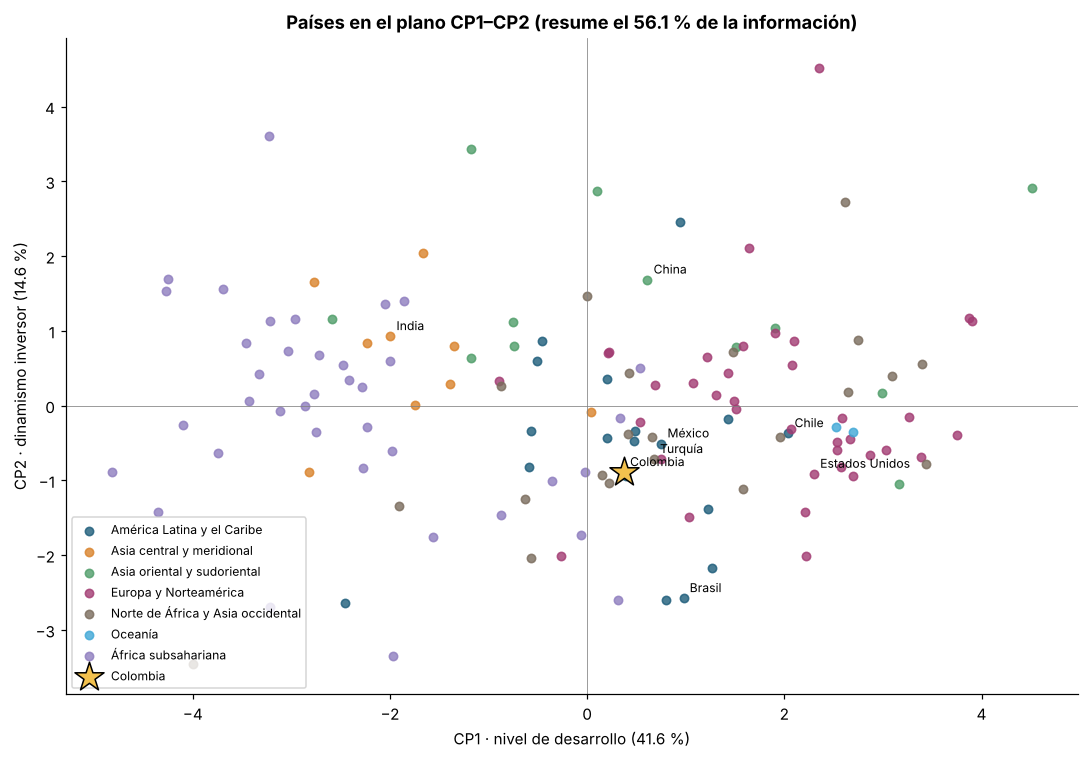

In [16]:
# Países en el plano CP1-CP2, coloreados por región, con Colombia resaltada
P = acp.puntajes.join(prep.meta)
fig, ax = plt.subplots(figsize=(10, 7))
for (reg, d), c in zip(P.groupby("region"), COLORES + ["#8e7dbe"]):
    ax.scatter(d["CP1"], d["CP2"], s=30, alpha=0.8, color=c, label=reg)
ax.scatter(*P.loc["COL", ["CP1", "CP2"]], marker="*", s=400, color="#f2c14e", edgecolor="black", zorder=5, label="Colombia")
for iso in ["COL", "CHL", "MEX", "BRA", "USA", "CHN", "IND", "TUR"]:
    ax.annotate(P.loc[iso, "pais"], P.loc[iso, ["CP1", "CP2"]], fontsize=8, xytext=(4, 4), textcoords="offset points")
p1, p2 = v["% varianza"].iloc[:2]
ax.set(title=f"Países en el plano CP1–CP2 (resume el {p1 + p2:.1f} % de la información)",
       xlabel=f"CP1 · nivel de desarrollo ({p1:.1f} %)", ylabel=f"CP2 · dinamismo inversor ({p2:.1f} %)")
ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
ax.legend(fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()

## 5. Segmentación con K-Means

K-Means se aplica sobre los **4 componentes conservados**: están en escala comparable, no están correlacionados y
concentran la señal. Se usan 50 inicializaciones y semilla fija (42) para que el resultado sea reproducible.

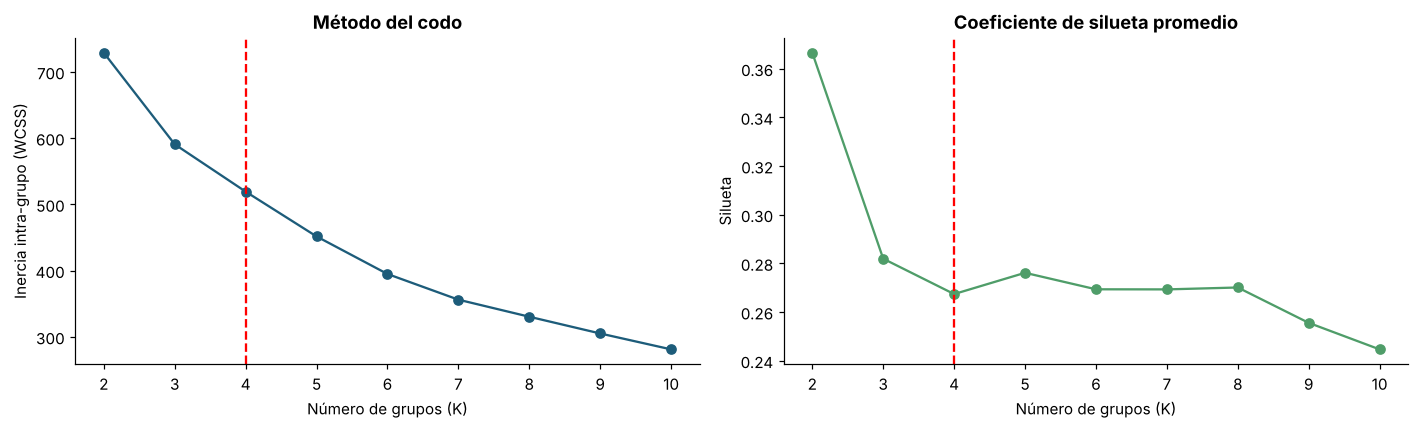

Codo (máxima curvatura): 6


,K,Inercia (WCSS),Silueta,Reducción de inercia (%)
0,2,728.749,0.367,NaN
1,3,590.546,0.282,18.964
2,4,519.114,0.267,12.096
3,5,451.472,0.276,13.030
4,6,394.783,0.269,12.557
5,7,356.000,0.269,9.824
6,8,330.242,0.270,7.235
7,9,304.973,0.256,7.652
8,10,280.961,0.245,7.873


In [17]:
X = acp.puntajes.iloc[:, :N_COMP]
tk = pl.evaluar_k(X)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(tk["K"], tk["Inercia (WCSS)"], "o-", color=AZUL); a1.axvline(K, ls="--", color="red")
a1.set(title="Método del codo", xlabel="Número de grupos (K)", ylabel="Inercia intra-grupo (WCSS)")
a2.plot(tk["K"], tk["Silueta"], "o-", color="#4f9d69"); a2.axvline(K, ls="--", color="red")
a2.set(title="Coeficiente de silueta promedio", xlabel="Número de grupos (K)", ylabel="Silueta")
plt.tight_layout(); plt.show()
print("Codo (máxima curvatura):", pl.k_codo(tk))
tk.round(3)

**Elección de K = 4.** La silueta más alta se obtiene con K = 2 (0,37), pero esa partición solo separa a los países de
ingreso alto del resto, lo mismo que ya muestra el CP1. Entre K = 3 y K = 6 la silueta es casi plana (0,27–0,28) y no
discrimina; el codo se ubica entre 4 y 6. K = 4 es el menor valor que, además del gradiente de ingreso, separa un grupo
definido por otra dimensión (inversión alta con déficit externo).

In [18]:
grupos, km = pl.ejecutar_kmeans(X, K)
med, z = pl.perfiles(prep.originales, prep.estandarizadas, grupos)
nombres = {g: pl.nombre_descriptivo(z.loc[g]) for g in z.index}
tabla = med.copy()
tabla.columns = ["N.º países"] + [nombre(c) for c in tabla.columns[1:]]
tabla.insert(0, "Rasgos más distintivos", [nombres[g] for g in tabla.index])
tabla.round(1)   # medianas en unidades originales

,Rasgos más distintivos,N.º países,PIB per cápita,Crecimiento del PIB,Inflación,Desempleo,Comercio exterior,IED,Cuenta corriente,Formación de capital,Crédito privado,Esperanza de vida,Urbanización,Uso de internet
grupo,,,,,,,,,,,,,,
Grupo A,"PIB per cápita alto, Uso de internet alto",44,31700.3,2.7,1.2,5.5,96.8,3.0,1.2,23.9,84.8,81.3,79.0,85.0
Grupo B,"Desempleo alto, Crecimiento del PIB bajo",37,6152.4,2.2,3.5,11.4,73.9,2.2,-2.1,21.3,39.4,73.5,69.3,59.3
Grupo C,"Uso de internet bajo, PIB per cápita bajo",33,1008.1,4.9,5.3,4.3,47.9,2.1,-4.1,22.8,14.3,63.4,34.8,16.8
Grupo D,"Formación de capital alta, Cuenta corriente baja",24,3182.8,4.4,2.6,4.9,84.1,3.0,-5.6,31.0,41.4,71.5,55.7,41.8


In [19]:
for g in sorted(grupos.unique()):
    print(f"{g} · {nombres[g]} ({(grupos == g).sum()}):")
    print("   ", ", ".join(prep.meta.loc[grupos[grupos == g].index, "pais"]), "\n")

Grupo A · PIB per cápita alto, Uso de internet alto (44):
    Emiratos Árabes Unidos, Australia, Austria, Bélgica, Bulgaria, Baréin, Canadá, Suiza, Chile, Costa Rica, Chipre, Chequia, Alemania, Dinamarca, España, Estonia, Finlandia, Francia, Reino Unido, Croacia, Hungría, Irlanda, Israel, Italia, Japón, Corea del Sur, Kuwait, Lituania, Letonia, Malasia, Países Bajos, Noruega, Nueva Zelanda, Omán, Polonia, Portugal, Catar, Arabia Saudí, Singapur, Eslovaquia, Eslovenia, Suecia, Tailandia, Estados Unidos 

Grupo B · Desempleo alto, Crecimiento del PIB bajo (37):
    Angola, Argentina, Armenia, Azerbaiyán, Bosnia y Herzegovina, Bielorrusia, Brasil, Botsuana, Colombia, Yibuti, Ecuador, Gabón, Guinea Ecuatorial, Grecia, Guatemala, Irak, Kazajistán, Líbano, Libia, Lesoto, México, Macedonia del Norte, Mauricio, Namibia, Perú, Paraguay, Territorios Palestinos, Rusia, El Salvador, Serbia, Esuatini, Trinidad y Tobago, Túnez, Turquía, Ucrania, Uruguay, Sudáfrica 

Grupo C · Uso de internet bajo, P

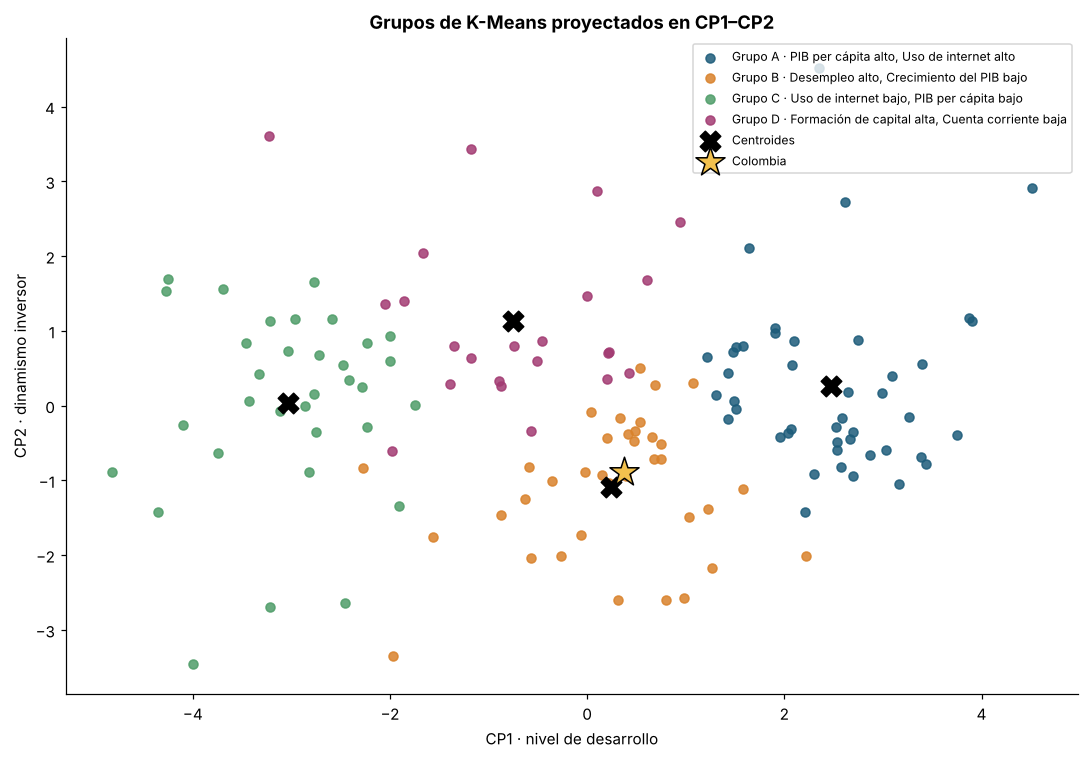

In [20]:
# Grupos en el plano CP1-CP2 (las letras son nombres, no un orden)
colg = dict(zip(sorted(grupos.unique()), COLORES))
fig, ax = plt.subplots(figsize=(10, 7))
for g in sorted(grupos.unique()):
    d = X[grupos == g]
    ax.scatter(d["CP1"], d["CP2"], s=35, alpha=0.85, color=colg[g], label=f"{g} · {nombres[g]}")
ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], marker="X", s=180, color="black", label="Centroides")
ax.scatter(*X.loc["COL", ["CP1", "CP2"]], marker="*", s=400, color="#f2c14e", edgecolor="black", zorder=5, label="Colombia")
ax.set(title="Grupos de K-Means proyectados en CP1–CP2", xlabel="CP1 · nivel de desarrollo", ylabel="CP2 · dinamismo inversor")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

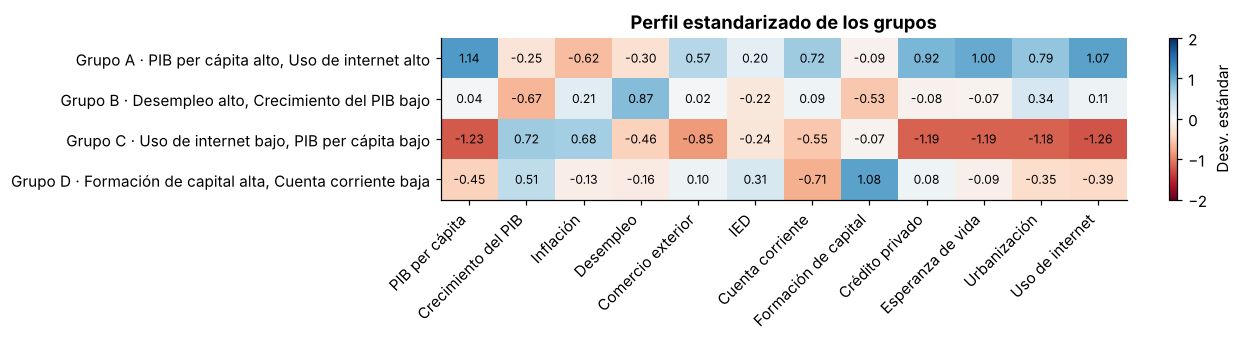

In [21]:
# Perfil estandarizado de cada grupo (desviaciones respecto a la media de la muestra)
zz = z.copy(); zz.columns = [nombre(c) for c in zz.columns]
fig, ax = plt.subplots(figsize=(12, 3.2))
im = ax.imshow(zz, cmap="RdBu", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(zz.shape[1]), zz.columns, rotation=45, ha="right")
ax.set_yticks(range(len(zz)), [f"{g} · {nombres[g]}" for g in zz.index])
for i in range(zz.shape[0]):
    for j in range(zz.shape[1]):
        ax.text(j, i, f"{zz.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Desv. estándar")
ax.set_title("Perfil estandarizado de los grupos"); plt.tight_layout(); plt.show()

- **Grupo A · Ingreso alto (44):** PIB per cápita mediano ≈ US$ 31.700, esperanza de vida 81 años, crédito privado ≈ 85 % del PIB, inflación ≈ 1 %. Incluye a Chile y Costa Rica.
- **Grupo B · Ingreso medio con desempleo alto y bajo crecimiento (37):** PIB per cápita ≈ US$ 6.150, desempleo 11,4 %, crecimiento 2,2 %. Aquí está **Colombia**, con México, Brasil, Perú, Argentina, Turquía y Sudáfrica.
- **Grupo C · Ingreso bajo en expansión (33):** PIB per cápita ≈ US$ 1.000 pero crecimiento de 4,9 %.
- **Grupo D · Inversión alta con déficit externo (24):** formación de capital 31 % del PIB y déficit externo −5,6 %; China, Vietnam, Indonesia, Panamá, Bolivia. **No lo define el ingreso.**

Silueta promedio: 0.267
grupo
Grupo A    0.329
Grupo B    0.209
Grupo C    0.368
Grupo D    0.106


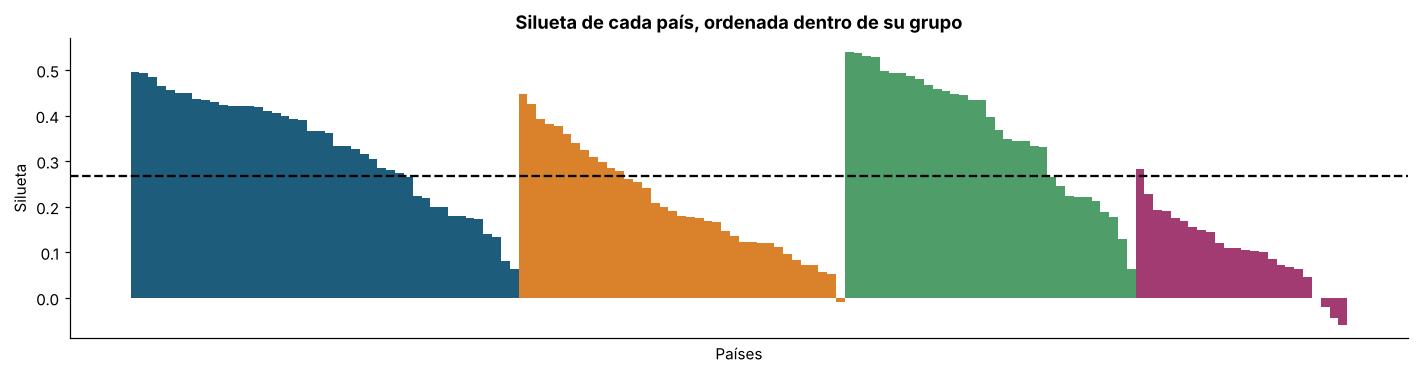

,pais,grupo,grupo_vecino,silueta
iso3,,,,
SEN,Senegal,Grupo D,Grupo C,-0.059
BOL,Bolivia,Grupo D,Grupo B,-0.044
DOM,República Dominicana,Grupo D,Grupo B,-0.020
LSO,Lesoto,Grupo B,Grupo C,-0.009
ALB,Albania,Grupo D,Grupo B,-0.001
MOZ,Mozambique,Grupo D,Grupo C,0.045


In [22]:
# Silueta por país y países frontera
sil = pl.silueta_por_pais(X, grupos, km)
print(f"Silueta promedio: {sil['silueta'].mean():.3f}")
print(sil.groupby("grupo")["silueta"].mean().round(3).to_string())
s = sil.sort_values(["grupo", "silueta"], ascending=[True, False])
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.bar(range(len(s)), s["silueta"], color=[colg[g] for g in s["grupo"]], width=1)
ax.axhline(sil["silueta"].mean(), ls="--", color="black")
ax.set(title="Silueta de cada país, ordenada dentro de su grupo", xlabel="Países", ylabel="Silueta", xticks=[])
plt.tight_layout(); plt.show()
frontera = sil[sil["silueta"] < 0.05].join(prep.meta["pais"]).sort_values("silueta")
frontera[["pais", "grupo", "grupo_vecino", "silueta"]].round(3)

In [23]:
# ¿Los grupos replican la clasificación por ingreso del Banco Mundial?
ct = pd.crosstab(grupos, prep.meta["grupo_ingreso"])[["Ingreso bajo", "Ingreso medio-bajo", "Ingreso medio-alto", "Ingreso alto"]]
print(f"V de Cramér: {pl.cramers_v(ct):.2f}")
ct

V de Cramér: 0.68


grupo_ingreso,Ingreso bajo,Ingreso medio-bajo,Ingreso medio-alto,Ingreso alto
grupo,,,,
Grupo A,0,0,4,40
Grupo B,0,8,26,3
Grupo C,20,13,0,0
Grupo D,2,14,7,1


La silueta promedio (≈ 0,27) indica una **estructura moderada**: los países forman más un continuo que grupos aislados.
Los grupos extremos (A y C) son compactos; los intermedios (B y D), difusos. La relación con la clasificación por ingreso
es fuerte pero imperfecta (V de Cramér ≈ 0,68): el grupo D mezcla todos los niveles de ingreso.

## 6. ¿Dónde está Colombia?

In [24]:
print(f"Colombia → {grupos['COL']} · {nombres[grupos['COL']]} · silueta {sil.loc['COL', 'silueta']:.2f} "
      f"· grupo alternativo más cercano: {sil.loc['COL', 'grupo_vecino']}")
vec = pl.vecinos(X, "COL", 10).rename("distancia").to_frame().join(prep.meta).join(grupos)
vec[["pais", "region", "grupo_ingreso", "grupo", "distancia"]].round(2)

Colombia → Grupo B · Desempleo alto, Crecimiento del PIB bajo · silueta 0.31 · grupo alternativo más cercano: Grupo D


,pais,region,grupo_ingreso,grupo,distancia
iso3,,,,,
TUR,Turquía,Norte de África y Asia occidental,Ingreso medio-alto,Grupo B,0.59
MEX,México,América Latina y el Caribe,Ingreso medio-alto,Grupo B,0.78
BLR,Bielorrusia,Europa y Norteamérica,Ingreso medio-alto,Grupo B,0.80
KAZ,Kazajistán,Asia central y meridional,Ingreso medio-alto,Grupo B,0.92
PER,Perú,América Latina y el Caribe,Ingreso medio-alto,Grupo B,1.11
ECU,Ecuador,América Latina y el Caribe,Ingreso medio-alto,Grupo B,1.13
SLV,El Salvador,América Latina y el Caribe,Ingreso medio-bajo,Grupo B,1.32
PRY,Paraguay,América Latina y el Caribe,Ingreso medio-alto,Grupo B,1.33
MAR,Marruecos,Norte de África y Asia occidental,Ingreso medio-bajo,Grupo D,1.40


In [25]:
latam = prep.meta.index[prep.meta["region"] == "América Latina y el Caribe"]
comp = pd.DataFrame({
    "Colombia": prep.originales.loc["COL"],
    "Mediana de su grupo": prep.originales.loc[grupos[grupos == grupos["COL"]].index].median(),
    "Mediana América Latina": prep.originales.loc[latam].median(),
    "Mediana mundo": prep.originales.median(),
})
comp.index = [nombre(i) for i in comp.index]
comp.round(1)

,Colombia,Mediana de su grupo,Mediana América Latina,Mediana mundo
PIB per cápita,6333.6,6152.4,6460.2,6014.1
Crecimiento del PIB,2.4,2.2,2.4,3.2
Inflación,4.7,3.5,3.1,2.0
Desempleo,9.2,11.4,5.8,5.3
Comercio exterior,36.8,73.9,52.5,69.4
IED,4.2,2.2,2.9,2.6
Cuenta corriente,-4.6,-2.1,-2.2,-2.2
Formación de capital,22.2,21.3,21.8,23.7
Crédito privado,47.1,39.4,43.5,43.3
Esperanza de vida,76.4,73.5,74.4,73.8


In [26]:
print("América Latina por grupo:")
for g in sorted(grupos.unique()):
    paises = prep.meta.loc[latam.intersection(grupos[grupos == g].index), "pais"]
    print(f"  {g}: {', '.join(paises) or '—'}")

América Latina por grupo:
  Grupo A: Chile, Costa Rica
  Grupo B: Argentina, Brasil, Colombia, Ecuador, Guatemala, México, Perú, Paraguay, El Salvador, Trinidad y Tobago, Uruguay
  Grupo C: Haití
  Grupo D: Bolivia, República Dominicana, Honduras, Nicaragua, Panamá


Colombia queda en el grupo de **ingreso medio con desempleo alto y bajo crecimiento**. Su vecino más cercano es
**Turquía**, seguido de México: el parecido no lo explica la región, porque América Latina se reparte en tres grupos
(Chile y Costa Rica con el ingreso alto; Panamá, Bolivia y República Dominicana con las economías de inversión alta). Su
rasgo más distintivo es la **baja apertura comercial** (comercio ≈ 37 % del PIB frente a ≈ 74 % de la mediana de su grupo).

## 7. Robustez

In [27]:
# a) Otro periodo: 2020-2024
r2 = pl.flujo_completo(periodo=(2020, 2024), n_comp=N_COMP, k=K)
print(f"ARI entre periodos: {pl.comparar_particiones(grupos, r2['grupos']):.2f}")
g2 = r2["grupos"]
print("Grupo con alta inflación en 2020-2024:",
      [", ".join(r2['prep'].meta.loc[g2[g2 == g].index, 'pais']) for g in g2.unique() if (g2 == g).sum() <= 6])

# b) Sin transformaciones
r3 = pl.flujo_completo(periodo=PERIODO, n_comp=N_COMP, k=K, aplicar_transformacion=False)
print(f"\nARI con/sin transformaciones: {pl.comparar_particiones(grupos, r3['grupos']):.2f}")
print("Tamaños sin transformar:", r3["grupos"].value_counts().to_dict())

# c) Núcleo estable: países que acompañan a Colombia para todo K entre 3 y 6
conjuntos = []
for kk in range(3, 7):
    gk, _ = pl.ejecutar_kmeans(X, kk)
    conjuntos.append(set(gk[gk == gk["COL"]].index) - {"COL"})
nucleo = set.intersection(*conjuntos)
print(f"\nNúcleo estable de Colombia ({len(nucleo)} países):", ", ".join(prep.meta.loc[sorted(nucleo), "pais"]))

ARI entre periodos: 0.36
Grupo con alta inflación en 2020-2024: ['Argentina, Haití, Líbano, Sudán, Zimbabue']



ARI con/sin transformaciones: 0.55
Tamaños sin transformar: {'Grupo A': 54, 'Grupo B': 41, 'Grupo C': 39, 'Grupo D': 4}

Núcleo estable de Colombia (26 países): Argentina, Armenia, Azerbaiyán, Bosnia y Herzegovina, Bielorrusia, Brasil, Botsuana, Ecuador, Grecia, Guatemala, Irak, Kazajistán, Líbano, México, Macedonia del Norte, Mauricio, Perú, Paraguay, Territorios Palestinos, Rusia, El Salvador, Serbia, Trinidad y Tobago, Túnez, Turquía, Uruguay


- **Periodo:** el ARI entre 2015–2019 y 2020–2024 (≈ 0,36) muestra que la partición cambia bastante. En 2020–2024 aparece un grupo de crisis inflacionaria (Argentina, Líbano, Sudán, Zimbabue, Haití) que ocupa uno de los cuatro grupos.
- **Transformaciones:** sin ellas, cuatro economías de enorme apertura e IED (Singapur, Irlanda, Chipre, Yibuti) forman un grupo propio.
- **K:** 26 países acompañan a Colombia para todo K entre 3 y 6 (entre ellos México, Brasil, Perú, Ecuador y Turquía): son sus pares más confiables.

## 8. Conclusiones y limitaciones

1. **El ingreso es la dimensión dominante, pero no la única:** el CP1 explica el 42 % de la variación; dinamismo, estabilidad y sector externo explican el resto.
2. **Se conserva el 74,5 % de la información** con 4 componentes.
3. **Hay diferencias reales entre grupos que no se ordenan por ingreso:** uno se define por desempleo alto y bajo crecimiento, otro por inversión alta con déficit externo.
4. **Los grupos son moderadamente distinguibles** (silueta ≈ 0,27): hay países frontera y la partición depende del periodo.
5. **Colombia se parece más a las grandes economías de ingreso medio con mercado laboral débil** (México, Perú, Brasil, Turquía) que al promedio de América Latina; su rasgo distintivo es la baja apertura comercial.

**Limitaciones:** sesgo de selección por faltantes (los países con estadísticas débiles quedan fuera), sensibilidad de los
grupos al periodo, a K y a las transformaciones, ausencia de variables fiscales e institucionales, carácter descriptivo
(no causal) e imputación de un dato en 12 países.